In [2]:
from pathlib import Path
import pandas as pd

raw = Path(r"C:\Users\Asus-U\Desktop\Optimisation project\ElectricityPrices") #vous remplacez les ... par le chemin vers le dossier raw
markets = ['DK1', 'DE', 'DK2', 'NO2', 'SE4']
summary = []

for market in markets:
    files = sorted((raw / market / 'Prices').glob('*.csv'))
    print(f'\n{market}: {len(files)} files')

    for file in files:
        data = pd.read_csv(file, nrows=2, sep=None, engine='python', encoding='utf-8-sig')
        print(file.name, '|', list(data.columns))
        summary.append({'market': market, 'file': file.name,
                        'columns': ', '.join(data.columns)})

pd.DataFrame(summary).to_csv(raw.parent / 'raw_price_discovery.csv', index=False)
print('\nDiscovery saved to raw_price_discovery.csv')



DK1: 11 files
DK1_2015-2016_Prices.csv | ['MTU (UTC)', 'Area', 'Sequence', 'Day-ahead Price (EUR/MWh)', 'Intraday Period (UTC)', 'Intraday Price (EUR/MWh)']
DK1_2016-2017_Prices.csv | ['MTU (UTC)', 'Area', 'Sequence', 'Day-ahead Price (EUR/MWh)', 'Intraday Period (UTC)', 'Intraday Price (EUR/MWh)']
DK1_2017-2018_Prices.csv | ['MTU (UTC)', 'Area', 'Sequence', 'Day-ahead Price (EUR/MWh)', 'Intraday Period (UTC)', 'Intraday Price (EUR/MWh)']
DK1_2018-2019_Prices.csv | ['MTU (UTC)', 'Area', 'Sequence', 'Day-ahead Price (EUR/MWh)', 'Intraday Period (UTC)', 'Intraday Price (EUR/MWh)']
DK1_2019-2020_Prices.csv | ['MTU (UTC)', 'Area', 'Sequence', 'Day-ahead Price (EUR/MWh)', 'Intraday Period (UTC)', 'Intraday Price (EUR/MWh)']
DK1_2020-2021_Prices.csv | ['MTU (UTC)', 'Area', 'Sequence', 'Day-ahead Price (EUR/MWh)', 'Intraday Period (UTC)', 'Intraday Price (EUR/MWh)']
DK1_2021-2022_Prices.csv | ['MTU (UTC)', 'Area', 'Sequence', 'Day-ahead Price (EUR/MWh)', 'Intraday Period (UTC)', 'Intraday Pr

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import matplotlib.pyplot as plt

root = Path(r"C:\Users\Asus-U\Desktop\Optimisation project") #vous remplacez les ... par le chemin vers le dossier root
markets = ['DK1', 'DE', 'DK2', 'NO2', 'SE4']
hedges = markets[1:]
price_column = 'Day-ahead Price (EUR/MWh)'
output = root / 'hedge_results'
output.mkdir(exist_ok=True)


def load_prices(market):
    folder = root / 'ElectricityPrices' / market / 'Prices'
    tables = []

    for file in sorted(folder.glob('*.csv')):
        data = pd.read_csv(file, sep=None, engine='python', encoding='utf-8-sig', dtype=str)
        time_column = 'MTU (UTC)' if market in ['DK1', 'DK2'] else 'MTU (CET/CEST)'

        start = data[time_column].str.split(' - ', regex=False).str[0]
        time = pd.to_datetime(start, format='%d/%m/%Y %H:%M:%S', errors='coerce')
        if market in ['DK1', 'DK2']:
            time = time.dt.tz_localize('UTC')
        else:
            time = time.dt.tz_localize('Europe/Berlin', ambiguous='NaT', nonexistent='NaT').dt.tz_convert('UTC')

        values = data[price_column].str.strip().str.replace(' ', '', regex=False)
        has_comma = values.str.contains(',', regex=False, na=False)
        values.loc[has_comma] = values.loc[has_comma].str.replace('.', '', regex=False).str.replace(',', '.', regex=False)
        prices = pd.to_numeric(values, errors='coerce')
        tables.append(pd.DataFrame({'time': time, market: prices}).dropna())

    if not tables:
        raise FileNotFoundError(f'No CSV files found for {market}: {folder}')
    results = []
    result = pd.concat(tables).sort_values('time')
    conflicts = result.groupby('time')[market].nunique()
    if (conflicts > 1).any():
        raise ValueError(f'Conflicting prices at repeated timestamps in {market}')
    
    result = result.drop_duplicates('time').set_index('time')
    print(f'{market}: {len(result):,} observations')
    return result


prices = pd.concat([load_prices(market) for market in markets], axis=1, join='inner').dropna().sort_index()
prices.to_csv(output / 'aligned_day_ahead_prices.csv')

hourly = prices.index.to_series().diff() == pd.Timedelta(hours=1)
changes = prices.diff().loc[hourly].dropna()
if len(changes) < 300:
    raise ValueError('Too few aligned hourly observations')

cut = int(len(changes) * 0.7)
train = changes.iloc[:cut]
test = changes.iloc[cut:]

X = train[hedges].to_numpy()
y = train['DK1'].to_numpy()


def variance(weights):
    return np.var(y - X @ weights, ddof=1)


fit = minimize(variance, x0=np.full(4, 0.2), method='SLSQP',
               bounds=[(0, 1)] * 4,
               constraints={'type': 'ineq', 'fun': lambda w: 1 - sum(w)},
               options={'maxiter': 3000, 'ftol': 1e-11})
if not fit.success:
    raise RuntimeError(fit.message)

weights = fit.x
weight_table = pd.DataFrame({'market': hedges, 'weight': weights})
weight_table.to_csv(output / 'optimal_weights.csv', index=False)

results = []
for name, data in [('train', train), ('test', test)]:
    unhedged = data['DK1']
    hedged = unhedged - data[hedges].to_numpy() @ weights
    v0, v1 = unhedged.var(), hedged.var()

    results.append({'sample': name, 'n': len(data),
                    'unhedged_variance': v0, 'hedged_variance': v1,
                    'unhedged_std': np.sqrt(v0), 'hedged_std': np.sqrt(v1),
                    'variance_reduction_pct': 100 * (1 - v1 / v0)})

    if name == 'test':
        comparison = pd.DataFrame({'unhedged_change': unhedged,
                                   'hedged_proxy_change': hedged}, index=data.index)
        comparison.to_csv(output / 'test_changes.csv')
        ax = comparison.rolling(24, min_periods=24).sum().plot(figsize=(11, 4))
        ax.set(title='Rolling 24-observation sum of hourly price changes', ylabel='EUR/MWh')
        plt.tight_layout()
        plt.savefig(output / 'rolling_24_observations.png', dpi=160)
        plt.close()

risk_table = pd.DataFrame(results)
risk_table.to_csv(output / 'risk_comparison.csv', index=False)
print('\nOptimal weights:\n', weight_table.to_string(index=False))
print('\nRisk comparison:\n', risk_table.to_string(index=False))
print('\nResults saved in:', output)
print('Spot-price proxy hedge only, not a futures trading backtest.')


DK1: 96,144 observations
DE: 63,561 observations
DK2: 96,144 observations
NO2: 87,610 observations
SE4: 87,610 observations

Optimal weights:
 market   weight
    DE 0.450390
   DK2 0.407056
   NO2 0.137922
   SE4 0.004633

Risk comparison:
 sample     n  unhedged_variance  hedged_variance  unhedged_std  hedged_std  variance_reduction_pct
 train 44272         315.772138        74.540005     17.769979    8.633655               76.394369
  test 18974         373.000189        54.289351     19.313213    7.368131               85.445222

Results saved in: C:\Users\Asus-U\Desktop\Optimisation project\hedge_results
Spot-price proxy hedge only, not a futures trading backtest.


In [4]:
"""CVaR hedge for DK1 hourly day-ahead price changes.
Run after 02_min_variance_simple.py.
"""
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import linprog
from scipy.sparse import csr_matrix, hstack, vstack, eye
import matplotlib.pyplot as plt

root = Path(r"C:\Users\Asus-U\Desktop\Optimisation project") #vous remplacez les ... par le chemin vers le dossier root
output = root / 'hedge_results'
hedges = ['DE', 'DK2', 'NO2', 'SE4']
confidence_levels = [0.95, 0.99]

prices = pd.read_csv(output / 'aligned_day_ahead_prices.csv', index_col=0, parse_dates=True)
prices = prices.sort_index()
consecutive = prices.index.to_series().diff() == pd.Timedelta(hours=1)
changes = prices.diff().loc[consecutive].dropna()
cut = int(len(changes) * 0.7)
train, test = changes.iloc[:cut], changes.iloc[cut:]

mv_table = pd.read_csv(output / 'optimal_weights.csv').set_index('market')
mv_weights = mv_table.loc[hedges, 'weight'].to_numpy()


def optimize_cvar(data, alpha):
    y = data['DK1'].to_numpy()
    X = data[hedges].to_numpy()
    n = len(y)

    objective = np.r_[np.zeros(4), 1, np.full(n, 1 / ((1 - alpha) * n))]

    scenario_constraints = hstack([
        csr_matrix(-X),
        csr_matrix(-np.ones((n, 1))),
        -eye(n, format='csr')
    ], format='csr')
    weight_constraint = hstack([
        csr_matrix(np.ones((1, 4))),
        csr_matrix((1, n + 1))
    ], format='csr')
    A = vstack([scenario_constraints, weight_constraint], format='csr')
    b = np.r_[-y, 1]
    bounds = [(0, 1)] * 4 + [(None, None)] + [(0, None)] * n

    solution = linprog(objective, A_ub=A, b_ub=b, bounds=bounds, method='highs')
    if not solution.success:
        raise RuntimeError(solution.message)
    return solution.x[:4]


def cvar(losses, alpha):
    losses = np.asarray(losses)
    threshold = np.quantile(losses, alpha)
    return threshold + np.maximum(losses - threshold, 0).mean() / (1 - alpha)


strategies = {'Unhedged': np.zeros(4), 'Minimum variance': mv_weights}
for alpha in confidence_levels:
    strategies[f'CVaR {alpha:.0%}'] = optimize_cvar(train, alpha)

weight_table = pd.DataFrame(strategies, index=hedges).T
weight_table.index.name = 'strategy'
weight_table.to_csv(output / 'cvar_weights.csv')

rows = []
for period, data in [('train', train), ('test', test)]:
    y = data['DK1'].to_numpy()
    X = data[hedges].to_numpy()
    for name, weights in strategies.items():
        residual = y - X @ weights
        rows.append({
            'sample': period, 'strategy': name, 'n': len(data),
            'std': residual.std(ddof=1),
            'variance': residual.var(ddof=1),
            'VaR_95': np.quantile(residual, 0.95),
            'CVaR_95': cvar(residual, 0.95),
            'VaR_99': np.quantile(residual, 0.99),
            'CVaR_99': cvar(residual, 0.99),
        })

report = pd.DataFrame(rows)
for alpha in confidence_levels:
    col = f'CVaR_{int(alpha * 100)}'
    baseline = report[report.strategy == 'Unhedged'].set_index('sample')[col]
    report[f'{col}_reduction_pct'] = report.apply(
        lambda r: 100 * (1 - r[col] / baseline.loc[r['sample']])
        if baseline.loc[r['sample']] != 0 else np.nan, axis=1)
report.to_csv(output / 'cvar_risk_comparison.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 5))
subset = report[report['sample'] == 'test']
ax.bar(subset['strategy'], subset['CVaR_95'])
ax.set(ylabel='CVaR 95% (EUR/MWh)', title='Out-of-sample upper-tail hourly price-change risk')
ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
fig.savefig(output / 'cvar_test_comparison.png', dpi=160)
plt.close(fig)

print('\nStrategy weights:\n', weight_table.round(4).to_string())
print('\nOut-of-sample risk comparison:\n',
      report[report['sample'] == 'test'].round(3).to_string(index=False))
print('\nSaved in:', output)
print('CVaR here measures the upper tail of residual hourly spot-price changes, not actual procurement costs.')



Strategy weights:
                       DE     DK2     NO2     SE4
strategy                                        
Unhedged          0.0000  0.0000  0.0000  0.0000
Minimum variance  0.4504  0.4071  0.1379  0.0046
CVaR 95%          0.3805  0.5357  0.0838  0.0000
CVaR 99%          0.5251  0.3426  0.1323  0.0000

Out-of-sample risk comparison:
 sample         strategy     n    std  variance  VaR_95  CVaR_95  VaR_99  CVaR_99  CVaR_95_reduction_pct  CVaR_99_reduction_pct
  test         Unhedged 18974 19.313   373.000  28.883   49.287  59.404   88.241                  0.000                  0.000
  test Minimum variance 18974  7.368    54.289   9.944   18.322  22.604   34.620                 62.825                 60.766
  test         CVaR 95% 18974  7.318    53.549   9.470   18.250  23.077   34.982                 62.972                 60.356
  test         CVaR 99% 18974  7.470    55.805  10.257   18.406  22.518   34.770                 62.654                 60.597

Saved in: C:\User

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(r'C:\Users\Asus-U\Desktop\Optimisation project')
OUT = ROOT / 'hedge_results'
FIG = OUT / 'presentation_graphs'
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 130, 'savefig.dpi': 220})
NAVY, BLUE, TEAL, GOLD = '#13243a', '#3274a1', '#2b9b91', '#d3a34a'

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / name, bbox_inches='tight', facecolor='white')
    plt.close()

def load_csv(name):
    path = OUT / name
    if not path.exists():
        raise FileNotFoundError(f'Missing {path}. Run the minimum-variance and CVaR scripts first.')
    return pd.read_csv(path)

prices = pd.read_csv(OUT / 'aligned_day_ahead_prices.csv', index_col=0, parse_dates=True)
prices = prices[['DK1', 'DE', 'DK2', 'NO2', 'SE4']].sort_index()
prices.index = pd.to_datetime(prices.index, utc=True)

# 1. Historical DK1 prices: monthly mean plus monthly 10th–90th percentile band
monthly = prices['DK1'].resample('MS').agg(['mean', lambda x: x.quantile(.1), lambda x: x.quantile(.9)])
monthly.columns = ['mean', 'p10', 'p90']
fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(monthly.index, monthly['p10'].to_numpy(), monthly['p90'].to_numpy(), color=BLUE, alpha=.17, label='10th–90th percentile')
ax.plot(monthly.index, monthly['mean'], color=NAVY, lw=2, label='Monthly mean')
ax.axvspan(pd.Timestamp('2021-01-01', tz='UTC'), pd.Timestamp('2023-12-31', tz='UTC'), color=GOLD, alpha=.10, label='2021–2023 period')
ax.set(title='DK1 day-ahead electricity prices: historical exposure', ylabel='EUR/MWh')
ax.legend(frameon=False, loc='upper left')
save('01_dk1_historical_prices.png')

# 2. Rolling 30-day volatility of hourly price levels (not price changes)
rolling_std = prices['DK1'].rolling(24*30, min_periods=24*20).std()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(rolling_std.index, rolling_std, color=BLUE, lw=1.5)
ax.set(title='DK1 electricity price uncertainty over time', ylabel='30-day rolling standard deviation (EUR/MWh)', xlabel='')
save('02_dk1_rolling_volatility.png')

# Use only truly consecutive aligned hours for changes
consecutive = prices.index.to_series().diff().eq(pd.Timedelta(hours=1))
changes = prices.diff().loc[consecutive].dropna()

# 3. Cross-market correlation heatmap
corr = changes.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.to_numpy(), vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(5), corr.columns)
ax.set_yticks(range(5), corr.index)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center',
                color='white' if abs(corr.iloc[i,j]) > .75 else NAVY)
fig.colorbar(im, ax=ax, shrink=.8, label='Correlation')
ax.set_title('Correlation of hourly electricity price changes', pad=15)
save('03_cross_market_correlations.png')

# 4. Strategy weights (uses reported optimized weights; not re-estimated)
weights = pd.DataFrame({
    'Minimum variance': [0.4504, 0.4071, 0.1379, 0.0046],
    'CVaR 95%': [0.3805, 0.5357, 0.0838, 0.0000],
    'CVaR 99%': [0.5251, 0.3426, 0.1323, 0.0000]
}, index=['DE', 'DK2', 'NO2', 'SE4']).T * 100
fig, ax = plt.subplots(figsize=(10, 4.5))
left = np.zeros(len(weights))
for market, color in zip(weights.columns, [NAVY, BLUE, TEAL, GOLD]):
    vals = weights[market].to_numpy()
    bars = ax.barh(weights.index, vals, left=left, color=color, label=market, height=.6)
    for bar, value, offset in zip(bars, vals, left):
        if value >= 7:
            ax.text(offset + value/2, bar.get_y()+bar.get_height()/2, f'{value:.1f}%',
                    color='white', ha='center', va='center', fontsize=10, fontweight='bold')
    left += vals
ax.invert_yaxis()
ax.set(xlim=(0, 105), xlabel='Hedge weight (%)', title='How the optimization objective changes hedge allocation')
ax.legend(ncol=4, loc='lower center', bbox_to_anchor=(.5, -.30), frameon=False)
save('04_optimal_hedge_weights.png')

# 5. Residual change distribution, aligned to the same test period
# Reconstruct CVaR test split from aligned data (70/30 chronological split)
split = int(.7 * len(changes))
test = changes.iloc[split:]
# The CVaR run reported 18,974 test observations. Stop rather than silently plot mismatched samples.
if len(test) != 18974:
    print(f'WARNING: reconstructed test size is {len(test)}, but CVaR results used 18,974. '
          'Distribution chart skipped to avoid a misleading comparison. Check preprocessing.')
else:
    y = test['DK1'].to_numpy()
    X = test[['DE','DK2','NO2','SE4']].to_numpy()
    residual_mv = y - X @ (weights.loc['Minimum variance'].to_numpy()/100)
    residual_c95 = y - X @ (weights.loc['CVaR 95%'].to_numpy()/100)
    low, high = np.quantile(np.concatenate([y, residual_mv, residual_c95]), [.005, .995])
    bins = np.linspace(low, high, 90)
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.hist(y, bins=bins, density=True, alpha=.35, color=GOLD, label='Unhedged DK1')
    ax.hist(residual_mv, bins=bins, density=True, alpha=.50, color=BLUE, label='Minimum variance')
    ax.hist(residual_c95, bins=bins, density=True, alpha=.35, color=TEAL, label='CVaR 95%')
    ax.set(title='Distribution of hourly price changes — out-of-sample', xlabel='Hourly price change (EUR/MWh)', ylabel='Density')
    ax.legend(frameon=False)
    save('05_before_after_distribution.png')

# 6. Reported out-of-sample tail-risk comparison
risk = pd.DataFrame({
    'Unhedged': [49.287, 88.241],
    'Minimum variance': [18.322, 34.620],
    'CVaR 95%': [18.250, 34.982],
    'CVaR 99%': [18.406, 34.770]
}, index=['CVaR 95%', 'CVaR 99%']).T
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(risk))
w = .36
ax.bar(x-w/2, risk['CVaR 95%'], width=w, label='CVaR 95%', color=BLUE)
ax.bar(x+w/2, risk['CVaR 99%'], width=w, label='CVaR 99%', color=TEAL)
ax.set_xticks(x, risk.index)
ax.set(ylabel='Average upper-tail hourly price change (EUR/MWh)', title='Out-of-sample tail risk: which hedge protects best?')
ax.legend(frameon=False)
save('06_cvar_risk_comparison.png')

print(f'Graphs saved to: {FIG}')
print('Files:', *sorted(p.name for p in FIG.glob('*.png')), sep='\n  ')


Graphs saved to: C:\Users\Asus-U\Desktop\Optimisation project\hedge_results\presentation_graphs
Files:
  01_dk1_historical_prices.png
  02_dk1_rolling_volatility.png
  03_cross_market_correlations.png
  04_optimal_hedge_weights.png
  05_before_after_distribution.png
  06_cvar_risk_comparison.png


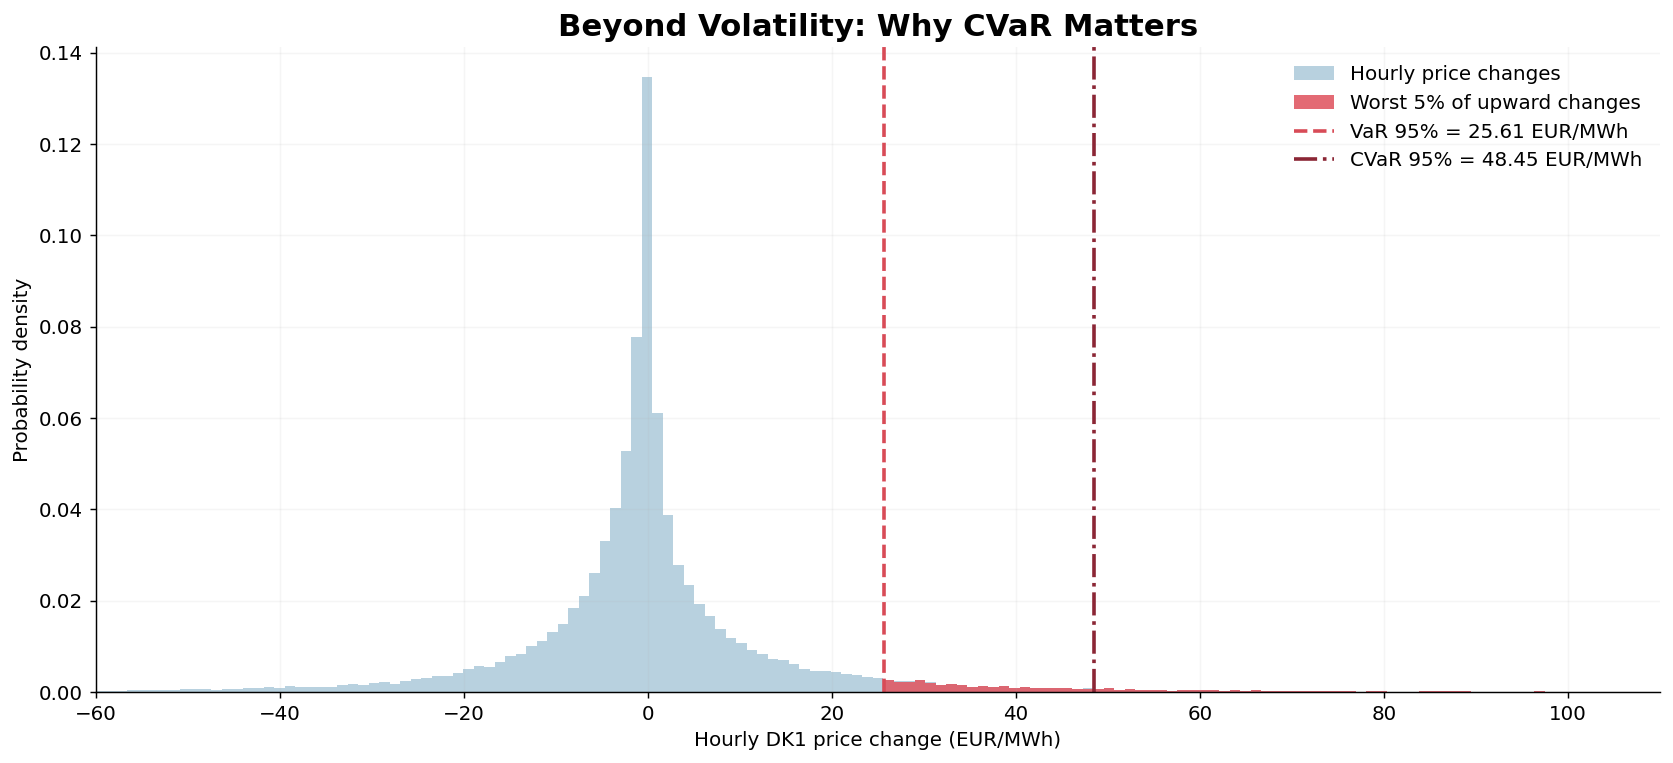

In [7]:
import numpy as np
import matplotlib.pyplot as plt

dk1 = prices["DK1"].dropna().sort_index()
delta = dk1.diff().dropna()

var95 = delta.quantile(0.95)
cvar95 = delta[delta >= var95].mean()

fig, ax = plt.subplots(figsize=(13, 6))

# Histogram
bins = np.linspace(-60, 110, 150)

ax.hist(
    delta,
    bins=bins,
    density=True,
    color="#A6C6D8",
    alpha=0.8,
    label="Hourly price changes"
)

# Highlight the upper 5% tail
ax.hist(
    delta[delta >= var95],
    bins=bins,
    weights=np.full(
        (delta >= var95).sum(),
        1 / (len(delta) * (bins[1] - bins[0]))
    ),
    color="#E05A65",
    alpha=0.9,
    label="Worst 5% of upward changes"
)

ax.axvline(
    var95, color="#D84B57",
    linestyle="--", linewidth=2,
    label=f"VaR 95% = {var95:.2f} EUR/MWh"
)

ax.axvline(
    cvar95, color="#8B2635",
    linestyle="-.", linewidth=2,
    label=f"CVaR 95% = {cvar95:.2f} EUR/MWh"
)

ax.set_xlim(-60, 110)

ax.set_title(
    "Beyond Volatility: Why CVaR Matters",
    fontsize=17, fontweight="bold"
)
ax.set_xlabel("Hourly DK1 price change (EUR/MWh)")
ax.set_ylabel("Probability density")

ax.legend(frameon=False, loc="upper right")
ax.grid(alpha=0.12)

plt.tight_layout()
plt.savefig("DK1_CVaR_Zoomed.png", dpi=300)
plt.show()